# Linear Algebra for Data Science 2026 — Lab 2, Core B
# Markov chains and PageRank

### <div align="right"> &copy; Rostyslav Hryniv, 2026, after O. Dyhdalovych & R. Hryniv, 2023 </div>

## Completed by:
*   Yulian Melnychuk
*   Artem Serbin

**Marked at the defence:** Core B is worth 2 points; the starred extension B1 at the end is one of three routes to the extension point (see the brief).

## Why this core

How popular is a web page, a paper or a user in a social network? PageRank answers with the stationary distribution of a random walk, which is an eigenvector of a huge, sparse, non-negative matrix. This core takes you from the naive model to the version that actually runs: you will see the model fail in three different ways, repair it with one rank-one term, **predict how fast the repaired iteration converges**, and run it on a graph with $10^5$ nodes without ever forming the matrix.

**Uses:** Lecture 3.2 (stochastic matrices, Perron–Frobenius, PageRank, power iteration). Core A's `power_method` is the same algorithm; here it gets a matrix-free form.

**Rules for this notebook**
* `np.linalg.eig`/`eigvals` are allowed **only to check** results on small graphs (§1, §3, §4). Your PageRank code must not call them.
* `networkx` is used for drawing small graphs, for generating the large test graph and, once, as an independent check in §5. Do not use it to compute ranks anywhere else.
* Every number you report must be reproduced by `Restart & Run All`.

In [1]:
import sys, time, numpy as np, scipy, scipy.sparse as sp, networkx as nx, matplotlib
import matplotlib.pyplot as plt
print('python', sys.version.split()[0], '| numpy', np.__version__, '| scipy', scipy.__version__,
      '| networkx', nx.__version__, '| matplotlib', matplotlib.__version__)
rng = np.random.default_rng(2026)   # do not change the seed: the defence uses your numbers

python 3.13.16 | numpy 2.1.3 | scipy 1.16.3 | networkx 3.7 | matplotlib 3.10.0


## The convention used throughout

Pages are numbered $0,\dots,n-1$. The **adjacency matrix** $G$ has
$$
G_{jk} = 1 \iff \text{page } k \text{ links to page } j,
$$
so **column $k$ lists the out-links of page $k$**, and the number of out-links $N_k$ is the $k$-th column sum. The link matrix of Lecture 3.2 is
$$
p_{jk} = \begin{cases} 1/N_k, & k \to j,\\ 0, & \text{otherwise,}\end{cases}
$$
so $p_{jk}$ is the probability of moving **from $k$ to $j$**, and every column of $P$ with $N_k > 0$ sums to $1$. Ranks are column vectors $\mathbf{r}$, updated by $\mathbf{r}_{n+1} = P\mathbf{r}_n$.

*(Last year's notebook stated this convention backwards in one place. If you find older material online, check its convention before reusing anything.)*

In [2]:
def plot_graph(G, ranks, title=''):
    # draws the graph with arrows k -> j for G[j, k] = 1, and the ranks under the labels
    graph = nx.from_numpy_array(np.asarray(G).T, create_using=nx.DiGraph)
    pos = nx.circular_layout(graph)
    plt.figure(figsize=(5, 4))
    nx.draw(graph, pos=pos, node_size=1600, node_color='w', edgecolors='k', linewidths=2,
            connectionstyle='arc3,rad=0.1', arrowsize=18)
    nx.draw_networkx_labels(graph, pos=pos, labels={v: f'{v}\n{ranks[v]:.3f}' for v in graph.nodes()})
    plt.title(title); plt.show()

---
## 1. The random surfer

### 1.1 Implement the two building blocks
* `link_matrix(G)` returns $P$ as above. Columns of pages with no out-links ("dead ends") stay zero for now.
* `power_markov(M, r0, tol, max_iter)` iterates $\mathbf{r}_{n+1} = M\mathbf{r}_n$. Here `M` may be a matrix **or a function** `x -> M x`; that is what will let you reuse it unchanged in §5. Stop when $\|\mathbf{r}_{n+1} - \mathbf{r}_n\|_1 \le$ `tol`. Return the final vector and a history with the 1-norm increments and the sums $\mathbf{1}^\top\mathbf{r}_n$.

**Question 1.1.** Core A normalised the iterate at every step. Why is no normalisation needed here, as long as $M$ is column-stochastic?

---
**Your answer**

If $M$ is column-stochastic then $\mathbf 1^\top M=\mathbf 1^\top$, so $\mathbf 1^\top(M\mathbf r)=\mathbf 1^\top\mathbf r$: the total probability is conserved exactly at every step. Since also $M\ge0$, a start $\mathbf r_0\ge0$ with sum $1$ stays a probability vector ($\|\mathbf r_n\|_1=1$ for all $n$), so it can neither blow up nor die out. In Core A the matrix was arbitrary: $\|A^n\mathbf r\|\sim|\lambda_1|^n$ grows or decays, so the iterate had to be rescaled. Here the dominant eigenvalue is exactly $\lambda_1=1$, so the scale is already fixed by the matrix.

---


In [3]:
def link_matrix(G):
    '''Column-stochastic link matrix P of Lecture 3.2; zero columns for dead ends.'''
    G = np.asarray(G, dtype=float)
    N = G.sum(axis=0)
    N[N == 0] = 1    # dead ends: the column stays zero
    return G / N

def power_markov(M, r0=None, tol=1e-10, max_iter=1000):
    '''
    Iterate r <- M r until ||r_new - r||_1 <= tol.
    M is an (n, n) array, a sparse matrix, or a function x -> M x.
    r0 defaults to the uniform distribution; then n must be inferable from M.
    Returns r and a dict with arrays 'inc' (1-norm increments) and 'sum' (sums of r_n).
    '''
    if callable(M):
        matvec = M
    else:
        matvec = lambda x: M @ x
    if r0 is None:
        if callable(M):
            raise ValueError('pass r0 when M is a function')
        n = M.shape[0]
        r = np.ones(n) / n
    else:
        r = np.array(r0, dtype=float)
    inc = []
    sums = [r.sum()]
    for _ in range(max_iter):
        r_new = np.ravel(matvec(r))
        inc.append(np.abs(r_new - r).sum())
        sums.append(r_new.sum())
        r = r_new
        if inc[-1] <= tol:
            break
    return r, {'inc': np.array(inc), 'sum': np.array(sums)}

### 1.2 First test
Run the iteration on the graph below from the uniform distribution and from two other starting distributions of your choice. Check the result against the eigenvector of $P$ for $\lambda = 1$ obtained from `np.linalg.eig` (normalise it to sum 1). Which page ranks highest? Explain *from the graph* why that is reasonable.

75 iterations, r = [0.206897 0.413793 0.137931 0.241379]
75 iterations, r = [0.206897 0.413793 0.137931 0.241379]
77 iterations, r = [0.206897 0.413793 0.137931 0.241379]
eigenvector: [0.206897 0.413793 0.137931 0.241379]
max difference from the eigenvector: 1.740274591099933e-13
in-links of the pages: [2 3 1 2]


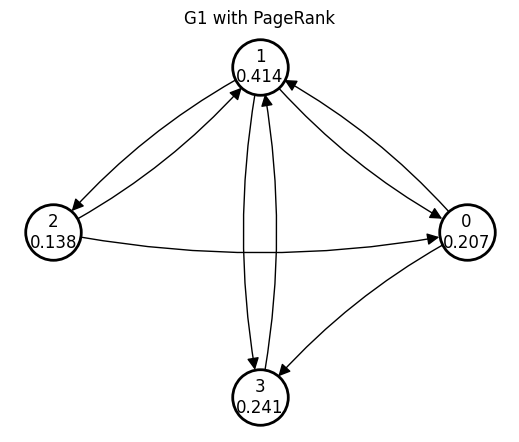

In [4]:
G1 = np.array([[0, 1, 1, 0],
               [1, 0, 1, 1],
               [0, 1, 0, 0],
               [1, 1, 0, 0]])
P1 = link_matrix(G1)
starts = [np.ones(4) / 4, np.array([1.0, 0, 0, 0]), np.array([0.1, 0.2, 0.3, 0.4])]

results = []
for r0 in starts:
    r, h = power_markov(P1, r0, tol=1e-12)
    results.append(r)
    print(len(h['inc']), 'iterations, r =', np.round(r, 6))

# eigenvector of P for lambda = 1
w, V = np.linalg.eig(P1)
i = np.argmin(np.abs(w - 1))
v = np.real(V[:, i])
v = v / v.sum()
print('eigenvector:', np.round(v, 6))
print('max difference from the eigenvector:', max(np.abs(r - v).max() for r in results))
print('in-links of the pages:', G1.sum(axis=1))
plot_graph(G1, v, 'G1 with PageRank')

---
**Your answer**

All three starts (uniform, $e_0$ and $(0.1,0.2,0.3,0.4)$) converge in 75-77 iterations (`tol=1e-12`) to the same vector
$\mathbf r=(6,12,4,7)/29\approx(0.2069,\,0.4138,\,0.1379,\,0.2414)$, which agrees with the normalised eigenvector of $P$ for $\lambda=1$ from `np.linalg.eig` to $\approx2\cdot10^{-13}$.

**Page 1 ranks highest.** It has the most in-links (three: from pages 0, 2 and 3, versus 2, 1, 2 for the others), and the links come from pages that pass on a large share of their rank: page 3 has page 1 as its *only* out-link, and pages 0 and 2 give it half of their rank each. Indeed $r_1=\tfrac12r_0+\tfrac12r_2+r_3=0.4138$.

---


---
## 2. Dead ends

### 2.1 What goes wrong
In the graph `G2` below, page 3 has no out-links. Run the iteration and plot the sums $\mathbf{1}^\top\mathbf{r}_n$ against $n$. Explain what you see using the column sums of $P$: show that $\mathbf{1}^\top\mathbf{r}_{n+1} = \mathbf{1}^\top\mathbf{r}_n - \mathbf{d}^\top\mathbf{r}_n$, where $\mathbf{d}$ marks the dead ends ($d_k = 1$ if $N_k = 0$, else $0$).

### 2.2 The repair
Let the surfer jump from a dead end to a uniformly random page:
$$
P_d := P + \tfrac1n\,\mathbf{1}\mathbf{d}^\top .
$$
Implement `fix_dead_ends(P)` and rerun. Check that $P_d$ is column-stochastic.

iterations: 58
first sums: [1.     0.75   0.5417 0.3542 0.2431 0.1632] , last sum: 1.5576512662028016e-10
largest |eigenvalue| of P: 0.6757598037736948
0.75 0.75
0.5416666666666666 0.5416666666666667
0.35416666666666663 0.35416666666666663
0.24305555555555552 0.24305555555555552
0.16319444444444442 0.16319444444444442


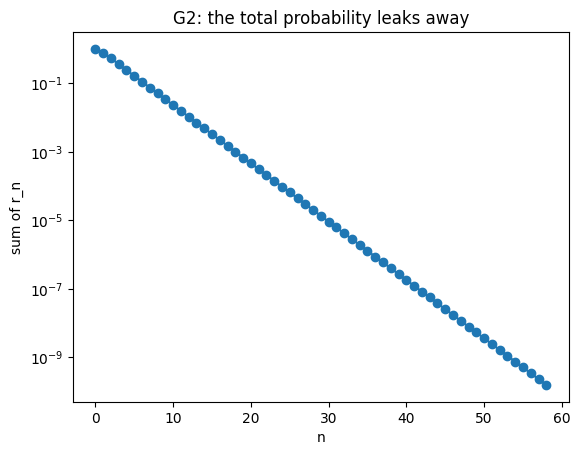

column sums of P_d: [1. 1. 1. 1.]
23 iterations, r = [0.252632 0.284211 0.168421 0.294737]
sums stay between 0.9999999999999992 and 1.0


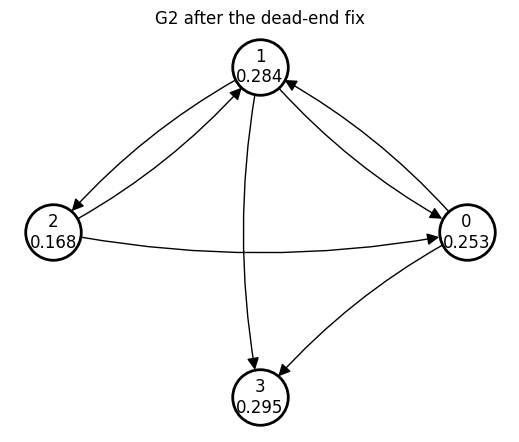

In [5]:
G2 = np.array([[0, 1, 1, 0],
               [1, 0, 1, 0],
               [0, 1, 0, 0],
               [1, 1, 0, 0]])

def fix_dead_ends(P):
    '''P_d = P + (1/n) 1 d^T (dense; for small graphs only).'''
    n = P.shape[0]
    d = (P.sum(axis=0) == 0).astype(float)
    return P + np.outer(np.ones(n), d) / n

# 2.1 the dead end
P2 = link_matrix(G2)
d2 = (P2.sum(axis=0) == 0).astype(float)
r, h = power_markov(P2)
print('iterations:', len(h['inc']))
print('first sums:', np.round(h['sum'][:6], 4), ', last sum:', h['sum'][-1])
print('largest |eigenvalue| of P:', np.abs(np.linalg.eigvals(P2)).max())

# check 1^T r_(n+1) = 1^T r_n - d^T r_n
r = np.ones(4) / 4
for n in range(5):
    r_next = P2 @ r
    print(r_next.sum(), r.sum() - d2 @ r)
    r = r_next

plt.semilogy(h['sum'], 'o-')
plt.xlabel('n')
plt.ylabel('sum of r_n')
plt.title('G2: the total probability leaks away')
plt.show()

# 2.2 the repair
Pd2 = fix_dead_ends(P2)
print('column sums of P_d:', Pd2.sum(axis=0))
r, h = power_markov(Pd2, tol=1e-12)
print(len(h['inc']), 'iterations, r =', np.round(r, 6))
print('sums stay between', h['sum'].min(), 'and', h['sum'].max())
plot_graph(G2, r, 'G2 after the dead-end fix')

---
**Your answer**

**2.1.** The sums $\mathbf 1^\top\mathbf r_n$ are $1,\,0.75,\,0.5417,\,0.3542,\,0.2431,\,0.1632,\dots$ and decay geometrically to $\approx1.6\cdot10^{-10}$ after 58 iterations (log-scale plot is a straight line): the probability leaks out and $\mathbf r_n\to\mathbf 0$. Reason: column $k$ of $P$ sums to $1$ if $N_k>0$ and to $0$ if $N_k=0$, i.e. $\mathbf 1^\top P=\mathbf 1^\top-\mathbf d^\top$. Hence
$$\mathbf 1^\top\mathbf r_{n+1}=\mathbf 1^\top P\mathbf r_n=\mathbf 1^\top\mathbf r_n-\mathbf d^\top\mathbf r_n,$$
so in every step the mass sitting on the dead end (here $r_3$) disappears. The printed check agrees: $0.75=1-0.25$, $0.5417=0.75-0.2083$, etc. The largest eigenvalue modulus of $P$ is $0.6758<1$, so $0$ is the only limit: the iteration converges, but to the useless vector $\mathbf 0$.

**2.2.** `fix_dead_ends` replaces the zero column by the uniform column $\frac1n\mathbf 1$. $P_d$ is column-stochastic (all column sums equal $1$, entries $\ge0$, checked), the sums $\mathbf 1^\top\mathbf r_n$ stay equal to $1$ to machine precision, and the iteration converges in 23 iterations to $\mathbf r=(0.2526,\,0.2842,\,0.1684,\,0.2947)$. The former dead end (page 3) now has the highest rank, because pages 0 and 1 link to it and it redistributes its rank to everybody.

---


---
## 3. When the answer is not unique, or the iteration does not settle

### 3.1 Three graphs, three problems
Run `power_markov` (on $P_d$) for the three graphs below, each from **at least three** starting distributions: the uniform one, $\mathbf{e}_0$, and one more. Use `max_iter=200`. For each graph, describe what happens. Then compute the eigenvalues of $P_d$ (here you may use `np.linalg.eigvals`), plot them in the complex plane together with the unit circle, and explain each behaviour **from the spectrum**.

* `G6`: does every page get a sensible rank? Does the iteration converge from every start?
* `G4` (a directed cycle): why does the uniform start *seem* to converge immediately?
* `G2c` (two separate parts): does the limit depend on the start?

G6 135 iterations, last increment 8.6e-11, r = [0.5 0.5 0.  0.  0.  0. ]
G6 200 iterations, last increment 2.0e+00, r = [1. 0. 0. 0. 0. 0.]
G6 200 iterations, last increment 1.9e-01, r = [0.4524 0.5476 0.     0.     0.     0.    ]

G4 1 iterations, last increment 0.0e+00, r = [0.25 0.25 0.25 0.25]
G4 200 iterations, last increment 2.0e+00, r = [1. 0. 0. 0.]
G4 200 iterations, last increment 6.0e-01, r = [0.1 0.2 0.3 0.4]

G2c 65 iterations, last increment 7.8e-11, r = [0.2 0.1 0.2 0.2 0.1 0.2]
G2c 70 iterations, last increment 5.8e-11, r = [0.4 0.2 0.4 0.  0.  0. ]
G2c 66 iterations, last increment 6.7e-11, r = [0.1143 0.0571 0.1143 0.2857 0.1429 0.2857]

left eigenvector for -1: [-1.      1.     -0.3333 -0.     -0.      0.3333]
overlap with the start: -0.0
overlap with the start: -1.0
overlap with the start: 0.0952


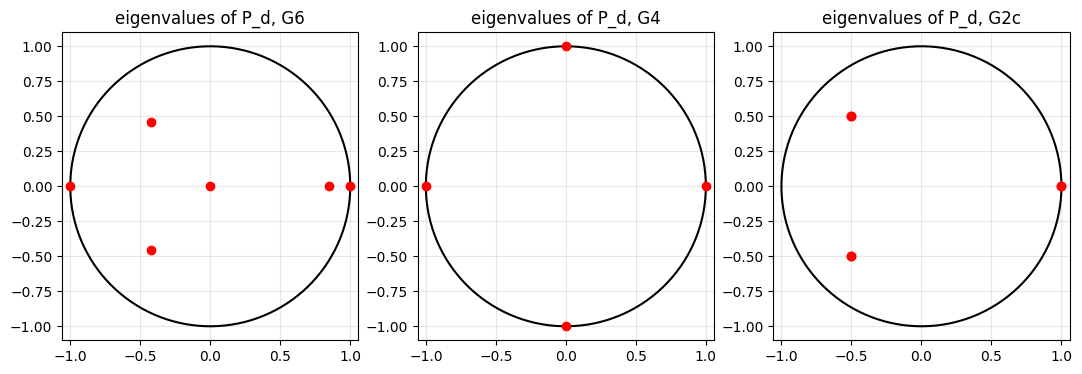

G6 [ 1.    +0.j     -1.    +0.j      0.8514+0.j     -0.4257+0.4586j
 -0.4257-0.4586j  0.    +0.j    ]
G4 [-1.+0.j  1.+0.j  0.+1.j  0.-1.j]
G2c [ 1. +0.j   1. +0.j  -0.5+0.5j -0.5-0.5j -0.5+0.5j -0.5-0.5j]


In [6]:
G6 = np.array([[0, 1, 0, 0, 0, 1],
               [1, 0, 1, 0, 0, 0],
               [0, 0, 0, 1, 0, 0],
               [0, 0, 1, 0, 1, 1],
               [0, 0, 1, 0, 0, 1],
               [0, 0, 0, 1, 0, 0]])
G4 = np.array([[0, 1, 0, 0],
               [0, 0, 1, 0],
               [0, 0, 0, 1],
               [1, 0, 0, 0]])
G2c = np.zeros((6, 6), dtype=int)
for k, j in [(0, 1), (1, 2), (2, 0), (0, 2), (3, 4), (4, 5), (5, 3), (3, 5)]:   # link k -> j
    G2c[j, k] = 1
def starts_for(n):
    ramp = np.arange(1, n + 1)
    return [np.ones(n) / n, np.eye(n)[0], ramp / ramp.sum()]

graphs = {'G6': G6, 'G4': G4, 'G2c': G2c}
Pd = {}
for name, G in graphs.items():
    Pd[name] = fix_dead_ends(link_matrix(G))

for name, M in Pd.items():
    for r0 in starts_for(len(M)):
        r, h = power_markov(M, r0, tol=1e-10, max_iter=200)
        print(name, len(h['inc']), 'iterations, last increment %.1e,' % h['inc'][-1], 'r =', np.round(r, 4))
    print()

# G6: left eigenvector of P_d for lambda = -1 and the overlap of each start with it
w, L = np.linalg.eig(Pd['G6'].T)
l = np.real(L[:, np.argmin(np.abs(w + 1))])
l = l / np.abs(l).max()
print('left eigenvector for -1:', np.round(l, 4))
for r0 in starts_for(6):
    print('overlap with the start:', round(l @ r0, 4))

# eigenvalues of P_d
theta = np.linspace(0, 2 * np.pi, 400)
plt.figure(figsize=(13, 4))
for i, (name, M) in enumerate(Pd.items()):
    ev = np.linalg.eigvals(M)
    plt.subplot(1, 3, i + 1)
    plt.plot(np.cos(theta), np.sin(theta), 'k-')
    plt.plot(ev.real, ev.imag, 'ro')
    plt.axis('equal')
    plt.grid(alpha=0.3)
    plt.title('eigenvalues of P_d, ' + name)
plt.show()

for name, M in Pd.items():
    ev = np.linalg.eigvals(M)
    ev = ev[np.argsort(-np.abs(ev))]
    print(name, np.round(ev, 4))

---
**Your answer**

**G6.** Pages 2-5 get rank $0$ and the iteration does not converge from every start. From the uniform start it converges (135 iterations) to $(\tfrac12,\tfrac12,0,0,0,0)$, but from $e_0$ and from the ramp start it does not settle (last increments $2.0$ and $0.19$). The spectrum of $P_d$ contains **two** eigenvalues of modulus 1, $\lambda=1$ and $\lambda=-1$, and the next one is $0.8514$. Pages 0 and 1 link only to each other: this closed pair is a *rank sink* (all the rank of the transient pages 2-5 eventually flows into it, so their limit rank is $0$) and it is a cycle of period 2, which gives $\lambda=-1$. The component of the start along the $\lambda=-1$ mode never decays; the iterates settle into a 2-cycle. The uniform start only converges because it has *exactly zero* overlap with that mode: the left eigenvector for $\lambda=-1$ is $\propto(-1,1,-\tfrac13,0,0,\tfrac13)$ and its inner product with the uniform vector is $0$ (printed $-0.0$), while for $e_0$ it is $-1$ and for the ramp start $0.095$.

**G4** (directed 4-cycle). $P_d=P$ is a permutation matrix; all four eigenvalues are the fourth roots of unity $1,i,-1,-i$, all on the unit circle. The uniform vector is the eigenvector for $\lambda=1$, so $P\mathbf r=\mathbf r$ and the iteration "converges" after one step (increment $0$). Any other start has components along $i,-1,-i$ which just rotate (period 4) and never decay: from $e_0$ the iterate walks $e_0\to e_1\to e_2\to e_3\to e_0$ (increment $2$ at every step), and the ramp start is permuted cyclically.

**G2c** (two separate parts). The iteration converges (65-70 iterations) but the limit depends on the start. $\lambda=1$ is a **double** eigenvalue of $P_d$ (one for each closed component), the next one has modulus $0.7071$. The stationary vectors form a 2-dimensional space; each component conserves its mass, so the limit is $m_A\boldsymbol\pi_A+m_B\boldsymbol\pi_B$ with $\boldsymbol\pi_A=\boldsymbol\pi_B=(0.4,0.2,0.4)$: uniform start gives $(0.2,0.1,0.2,0.2,0.1,0.2)$, $e_0$ gives $(0.4,0.2,0.4,0,0,0)$, the ramp start (masses $6/21$ and $15/21$) gives $(0.1143,0.0571,0.1143,0.2857,0.1429,0.2857)$.

So the three failures correspond to three spectral defects of $P_d$: another eigenvalue of modulus 1 other than $1$ ($-1$ for G6, $\pm i,-1$ for G4: no convergence), and a repeated eigenvalue $1$ (G2c: no unique limit); G6 additionally has a rank sink.

---


### 3.2 The repair: damping
With $0 < \alpha < 1$ (Google's choice was $\alpha \approx 0.85$), the surfer follows a link with probability $\alpha$ and jumps to a uniformly random page with probability $1-\alpha$:
$$
\widetilde P := \alpha P_d + \frac{1-\alpha}{n}\,\mathbf{1}\mathbf{1}^\top .
$$
*Careful: here, as in the lecture, $\alpha$ is the probability of **following a link**. Last year's notebook used $\alpha$ for the jump probability, i.e. our $1-\alpha$.*

**(a)** Show that $\widetilde P$ is column-stochastic and entrywise positive. What does Perron–Frobenius (Lecture 3.2) then guarantee?

**(b)** Prove the bound from the lecture: every eigenvalue $\lambda \ne 1$ of $\widetilde P$ satisfies $|\lambda| \le \alpha$. *Hint:* let $\widetilde P\mathbf{w} = \lambda\mathbf{w}$ with $\lambda \ne 1$. Use $\mathbf{1}^\top\widetilde P = \mathbf{1}^\top$ to show that $\mathbf{1}^\top\mathbf{w} = 0$, and conclude that $\lambda/\alpha$ is an eigenvalue of $P_d$. Why can no eigenvalue of a column-stochastic matrix exceed 1 in modulus? *(Consider the norm $\|\cdot\|_1$.)*

---
**Your answer**

**(a)** Column sums: $\mathbf 1^\top\widetilde P=\alpha\mathbf 1^\top P_d+\frac{1-\alpha}{n}(\mathbf 1^\top\mathbf 1)\mathbf 1^\top=\alpha\mathbf 1^\top+(1-\alpha)\mathbf 1^\top=\mathbf 1^\top$, using $\mathbf 1^\top P_d=\mathbf 1^\top$ and $\mathbf 1^\top\mathbf 1=n$. Positivity: $P_d\ge0$ and $\alpha>0$, so every entry of $\widetilde P$ is at least $(1-\alpha)/n>0$. By Perron-Frobenius a positive column-stochastic matrix has: the eigenvalue $1$ equals the spectral radius, it is **simple**, it has a strictly positive eigenvector (unique when normalised to sum 1: the PageRank vector), and **every other eigenvalue has modulus $<1$**. Hence power iteration converges to the PageRank vector from every starting distribution.

**(b)** Let $\widetilde P\mathbf w=\lambda\mathbf w$, $\mathbf w\neq0$, $\lambda\neq1$. Multiply by $\mathbf 1^\top$ and use $\mathbf 1^\top\widetilde P=\mathbf 1^\top$: $\mathbf 1^\top\mathbf w=\lambda\,\mathbf 1^\top\mathbf w$, so $(1-\lambda)\mathbf 1^\top\mathbf w=0$ and $\mathbf 1^\top\mathbf w=0$. Then the rank-one term vanishes:
$$\lambda\mathbf w=\widetilde P\mathbf w=\alpha P_d\mathbf w+\frac{1-\alpha}{n}\mathbf 1\,(\mathbf 1^\top\mathbf w)=\alpha P_d\mathbf w,$$
so $P_d\mathbf w=(\lambda/\alpha)\mathbf w$, i.e. $\lambda/\alpha$ is an eigenvalue of $P_d$. For a column-stochastic $Q$ and $Q\mathbf v=\mu\mathbf v$: $\|Q\mathbf v\|_1=\sum_j\bigl|\sum_kq_{jk}v_k\bigr|\le\sum_k|v_k|\sum_jq_{jk}=\|\mathbf v\|_1$, hence $|\mu|\le1$ (the induced 1-norm of a column-stochastic matrix is $1$). Applying this to $Q=P_d$, $\mu=\lambda/\alpha$ gives $|\lambda|\le\alpha$. $\square$

(The same computation read backwards shows: if $P_d\mathbf w=\mu\mathbf w$ with $\mathbf 1^\top\mathbf w=0$, then $\widetilde P\mathbf w=\alpha\mu\mathbf w$. This is used in §4.)

---


### 3.3 Implement and test
Write `google_matrix(G, alpha)` (dense — small graphs only) and rerun the three graphs of §3.1 from the same starts. Does the iteration converge now, and to a unique answer? Then, for `G6`, tabulate the ranks for $\alpha \in \{0.5, 0.85, 0.99\}$. What happens to pages 2–5 as $\alpha \to 1$, and why?

In [7]:
def google_matrix(G, alpha=0.85):
    n = len(G)
    Pd = fix_dead_ends(link_matrix(G))
    return alpha * Pd + (1 - alpha) / n * np.ones((n, n))

for name, G in graphs.items():
    Pt = google_matrix(G, 0.85)
    print(name, ', column sums equal 1:', np.allclose(Pt.sum(axis=0), 1), ', smallest entry:', Pt.min())
    limits = []
    for r0 in starts_for(len(G)):
        r, h = power_markov(Pt, r0, tol=1e-10, max_iter=200)
        limits.append(r)
        print('  ', len(h['inc']), 'iterations, r =', np.round(r, 4))
    print('  largest difference between the limits:', max(np.abs(x - limits[0]).max() for x in limits))
    print()

# G6 for different alpha
for alpha in [0.5, 0.85, 0.99]:
    r, h = power_markov(google_matrix(G6, alpha), tol=1e-12, max_iter=20000)
    print(alpha, len(h['inc']), 'iterations, r =', np.round(r, 4), ', total rank of pages 2-5:', round(r[2:].sum(), 4))

G6 , column sums equal 1: True , smallest entry: 0.025000000000000005
   67 iterations, r = [0.3188 0.3188 0.0805 0.1307 0.0706 0.0805]
   147 iterations, r = [0.3188 0.3188 0.0805 0.1307 0.0706 0.0805]
   132 iterations, r = [0.3188 0.3188 0.0805 0.1307 0.0706 0.0805]
  largest difference between the limits: 8.248962624080036e-11

G4 , column sums equal 1: True , smallest entry: 0.037500000000000006
   1 iterations, r = [0.25 0.25 0.25 0.25]
   147 iterations, r = [0.25 0.25 0.25 0.25]
   140 iterations, r = [0.25 0.25 0.25 0.25]
  largest difference between the limits: 3.159583705780733e-11

G2c , column sums equal 1: True , smallest entry: 0.025000000000000005
   45 iterations, r = [0.1939 0.1074 0.1987 0.1939 0.1074 0.1987]
   132 iterations, r = [0.1939 0.1074 0.1987 0.1939 0.1074 0.1987]
   126 iterations, r = [0.1939 0.1074 0.1987 0.1939 0.1074 0.1987]
  largest difference between the limits: 1.1686188128301467e-10

0.5 31 iterations, r = [0.2103 0.2103 0.131  0.1905 0.127  0.13

---
**Your answer**

With damping ($\alpha=0.85$) the iteration converges for all three graphs from all three starts (last increments $\le10^{-10}$), and the limit is **the same for every start** (largest difference between limits $\approx10^{-10}$, i.e. the tolerance): G6 $\to(0.3188,0.3188,0.0805,0.1307,0.0706,0.0805)$ (every page now has a positive rank), G4 $\to(0.25,0.25,0.25,0.25)$ (the iteration from $e_0$ converges in 147 steps, no more rotating), G2c $\to(0.1939,0.1074,0.1987,0.1939,0.1074,0.1987)$ (unique). This is the Perron-Frobenius statement of 3.2(a): simple eigenvalue $1$, all others of modulus $\le\alpha<1$.

G6, dependence on $\alpha$:

| $\alpha$ | iterations (tol $10^{-12}$) | $r_0=r_1$ | total rank of pages 2-5 |
|---|---|---|---|
| 0.5 | 31 | 0.2103 | 0.5794 |
| 0.85 | 81 | 0.3188 | 0.3624 |
| 0.99 | 154 | 0.4787 | 0.0426 |

As $\alpha\to1$ the ranks of pages 2-5 tend to $0$ and all rank piles up on pages 0 and 1. Nothing links from $\{0,1\}$ back to pages 2-5, so these pages receive rank only through the teleportation term $(1-\alpha)/n$ (and from each other), which is of order $(1-\alpha)$ (for $\alpha=0.99$: $0.0426\approx4.3\,(1-\alpha)$). $\widetilde P\to P_d$ as $\alpha\to1$, whose limit (for the uniform start) is $(\tfrac12,\tfrac12,0,0,0,0)$. Also, the number of iterations grows with $\alpha$ because the convergence factor is at most $\alpha$.

---


---
## 4. How fast? Predict, then measure

By §3.2(b), the error of power iteration on $\widetilde P$ shrinks by at least the factor $\alpha$ per step.

**(a) Predict.** How many iterations should it take for the increment $\|\mathbf{r}_{n+1}-\mathbf{r}_n\|_1$ to fall from about $1$ to $10^{-10}$ for $\alpha = 0.85$? For $\alpha = 0.99$? Write the numbers down before you run anything.

---
**Your answer**

Prediction, written before running anything: the increments shrink at least by the factor $\alpha$ per step, $\|\mathbf r_{n+1}-\mathbf r_n\|_1\le\alpha^n\|\mathbf r_1-\mathbf r_0\|_1$ with $\|\mathbf r_1-\mathbf r_0\|_1\lesssim1$. We need $\alpha^n\le10^{-10}$, i.e. $n\ge\ln(10^{-10})/\ln\alpha=23.03/(-\ln\alpha)$:

* $\alpha=0.85$: $23.03/0.1625\approx141.7\Rightarrow$ **142 iterations**;
* $\alpha=0.99$: $23.03/0.01005\approx2291.1\Rightarrow$ **2292 iterations**.

These are *upper bounds* for the worst case, and the number of iterations scales like $1/(1-\alpha)$.

---


**(b) Measure.** The cell below generates a random directed graph with $n = 300$ pages, average out-degree about 5 and some dead ends. For $\alpha \in \{0.5, 0.7, 0.85, 0.95, 0.99\}$ compute
* the measured rate: the median of the ratios of successive increments, taken over the steps where the increment lies between $10^{-3}$ and $10^{-9}$;
* $|\lambda_2(\widetilde P)|$ from `np.linalg.eigvals` (the largest modulus apart from $\lambda = 1$);
* the bound $\alpha$.

Show a table and a plot of the increments against $n$. Is the bound $\alpha$ attained? Compute $|\lambda_2(\widetilde P)|/\alpha$ for each $\alpha$: what do you notice?

**(c) When is the bound sharp?** Repeat the measurement for `G2c` from §3. Explain the difference using the proof of §3.2(b). Real web graphs contain many pages and groups of pages with no links out of the group. Which of the two cases is the realistic one?

A_rand, uniform start
alpha, iterations to 1e-10, median rate, geometric-mean rate, |lambda_2|, |lambda_2|/alpha
0.5 17 0.2459 0.2473 0.25 0.5
0.7 21 0.3431 0.3435 0.35 0.5
0.85 26 0.4143 0.4115 0.425 0.5
0.95 29 0.4566 0.4551 0.475 0.5
0.99 31 0.4724 0.4719 0.495 0.5

G2c, start e_0
alpha, iterations to 1e-10, median rate, geometric-mean rate, |lambda_2|, |lambda_2|/alpha
0.5 34 0.5 0.5 0.5 1.0
0.7 63 0.7 0.7 0.7 1.0
0.85 132 0.85 0.85 0.85 1.0
0.95 392 0.95 0.95 0.95 1.0
0.99 1834 0.99 0.99 0.99 1.0

G2c, uniform start, alpha = 0.85
iterations to 1e-10: 45
median ratio: 0.8499999726335405 , geometric mean: 0.6172797130770645
first ratios: [0.85  0.85  0.425 0.425 0.85  0.85  0.425 0.425]


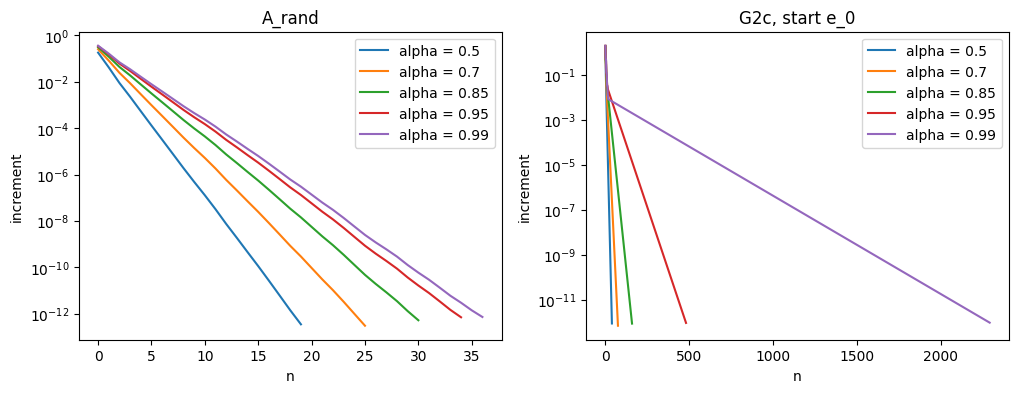

In [8]:
n = 300
A_rand = (rng.random((n, n)) < 5 / n).astype(int)
np.fill_diagonal(A_rand, 0)
A_rand[:, rng.choice(n, 15, replace=False)] = 0     # 15 dead ends
alphas = [0.5, 0.7, 0.85, 0.95, 0.99]

def measured_rate(h, lo=1e-9, hi=1e-3):
    # median ratio of successive increments while the increment is between lo and hi
    inc = h['inc']
    ok = (inc[:-1] <= hi) & (inc[1:] >= lo)
    return np.median(inc[1:][ok] / inc[:-1][ok])

def geo_rate(h, lo=1e-9, hi=1e-3):
    # geometric mean of the same ratios
    inc = h['inc']
    ok = (inc[:-1] <= hi) & (inc[1:] >= lo)
    return np.exp(np.mean(np.log(inc[1:][ok] / inc[:-1][ok])))

def lam2(M):
    ev = np.linalg.eigvals(M)
    ev = ev[np.argsort(-np.abs(ev))]
    return abs(ev[1])

def rate_study(G, r0=None):
    print('alpha, iterations to 1e-10, median rate, geometric-mean rate, |lambda_2|, |lambda_2|/alpha')
    hists = {}
    for alpha in alphas:
        Pt = google_matrix(G, alpha)
        r, h = power_markov(Pt, r0, tol=1e-12, max_iter=20000)
        hists[alpha] = h
        l2 = lam2(Pt)
        it = np.argmax(h['inc'] <= 1e-10) + 1
        print(alpha, it, round(measured_rate(h), 4), round(geo_rate(h), 4), round(l2, 4), round(l2 / alpha, 4))
    return hists

print('A_rand, uniform start')
hist_rand = rate_study(A_rand)
print()
print('G2c, start e_0')
hist_2c = rate_study(G2c, np.eye(6)[0])
print()

# G2c from the uniform start
_, h = power_markov(google_matrix(G2c, 0.85), tol=1e-12, max_iter=20000)
print('G2c, uniform start, alpha = 0.85')
print('iterations to 1e-10:', np.argmax(h['inc'] <= 1e-10) + 1)
print('median ratio:', measured_rate(h), ', geometric mean:', geo_rate(h))
print('first ratios:', np.round(h['inc'][1:9] / h['inc'][:8], 3))

plt.figure(figsize=(12, 4))
for i, (title, hists) in enumerate([('A_rand', hist_rand), ('G2c, start e_0', hist_2c)]):
    plt.subplot(1, 2, i + 1)
    for alpha, h in hists.items():
        plt.semilogy(h['inc'], label='alpha = ' + str(alpha))
    plt.xlabel('n')
    plt.ylabel('increment')
    plt.title(title)
    plt.legend()
plt.show()

---
**Your answer**

**(b)** Results (`it@1e-10` = number of iterations until the increment is $\le10^{-10}$; median = prescribed estimator; geo-mean = geometric mean of the ratios in the same window):

| $\alpha$ | it@1e-10 | median | geo-mean | $\lvert\lambda_2\rvert$ | bound $\alpha$ | $\lvert\lambda_2\rvert/\alpha$ |
|---|---|---|---|---|---|---|
| 0.50 | 17 | 0.2459 | 0.2473 | 0.2500 | 0.50 | 0.5000 |
| 0.70 | 21 | 0.3431 | 0.3435 | 0.3500 | 0.70 | 0.5000 |
| 0.85 | 26 | 0.4143 | 0.4115 | 0.4250 | 0.85 | 0.5000 |
| 0.95 | 29 | 0.4566 | 0.4551 | 0.4750 | 0.95 | 0.5000 |
| 0.99 | 31 | 0.4724 | 0.4719 | 0.4950 | 0.99 | 0.5000 |

The bound $\alpha$ is **not attained** on this graph: the measured rate is close to $|\lambda_2|$ (within 5%; slightly lower because the window still contains faster modes of modulus $\approx0.95|\lambda_2|$) and $|\lambda_2|\approx\alpha/2$. The ratio $|\lambda_2|/\alpha$ is **the same for all $\alpha$** ($0.49998$; the printout rounds it to $0.5$). The reason is the identity from 3.2(b) in both directions: the eigenvalues of $\widetilde P$ other than $1$ are exactly $\alpha$ times the eigenvalues of $P_d$ other than $1$, so $|\lambda_2(\widetilde P)|=\alpha\,|\mu_2|$, where $|\mu_2|=0.49998$ is a property of the graph alone. (That it is so close to $\tfrac12$ is a coincidence of this particular random graph.) Consequently the bound of §4(a) is far too pessimistic here: the iteration needs $26$ steps for $\alpha=0.85$ (prediction: $142$) and only $31$ steps for $\alpha=0.99$ (prediction: $2292$), and the number of steps hardly grows with $\alpha$.

**(c)** For `G2c`, started from $e_0$, the measured rate equals $\alpha$ for every $\alpha$ (median = geo-mean = $|\lambda_2|=\alpha$ to four digits), so $|\lambda_2|/\alpha=1.0000$: the bound is **attained**. The iteration counts to $10^{-10}$ are 34, 63, 132, 392, 1834 for $\alpha=0.5,\dots,0.99$ (bounds: 34, 65, 142, 449, 2292), i.e. below the bound only by a constant factor (the amplitude of the slow mode is smaller than $1$) but with exactly the predicted scaling $\propto1/(1-\alpha)$. Explanation from the proof of 3.2(b): the step "$\lambda/\alpha$ is an eigenvalue of $P_d$" is an equivalence for eigenvectors with $\mathbf 1^\top\mathbf w=0$, so $|\lambda_2(\widetilde P)|=\alpha$ exactly when $P_d$ has an eigenvalue $\mu$ with $|\mu|=1$ other than the Perron one. `G2c` has a *double* eigenvalue $1$ (two closed groups), so there is $\mathbf w=\boldsymbol\pi_A-\boldsymbol\pi_B$ with $\mathbf 1^\top\mathbf w=0$ and $P_d\mathbf w=\mathbf w$, hence $\widetilde P\mathbf w=\alpha\mathbf w$: damping shrinks the slow mode by exactly $\alpha$ and no more. In `A_rand` all eigenvalues of $P_d$ other than $1$ are strictly inside the unit disc, so damping only helps.

*A warning about the estimator.* With the **uniform** start on `G2c` the mass of the two components is equal, so the start has no component along $\mathbf w$, and the iteration needs only 45 steps. The prescribed median ratio then reports $0.8500$, which is an artefact: the dominant pair of eigenvalues is complex (modulus $0.7071\,\alpha=0.601$, argument $135^\circ$), the increments are not monotone and the successive ratios alternate $0.85,\,0.85,\,0.425,\,0.425,\dots$; the geometric mean gives $0.617\approx0.601$. Use the geometric mean (or $e_0$) when the dominant eigenvalue may be complex.

**Which case is realistic?** The case of `G2c`. Real web graphs contain many closed groups (closed sites, link farms, spider traps, small communities with no links out), so $P_d$ has an eigenvalue $1$ of high multiplicity and $|\lambda_2(\widetilde P)|=\alpha$ exactly, the bound is sharp, and the speed is governed by $\alpha$ only. §5 confirms this: with 300 spider traps the measured rate is $0.846\approx\alpha$.

---


---
## 5. Matrix-free PageRank on $10^5$ pages

### 5.1 The graph
The cell below builds a directed graph with about $10^5$ pages and stores its adjacency matrix in sparse form, with our convention $G_{jk} = 1 \iff k\to j$. It has two parts:
* $100\,000$ pages generated by `networkx.scale_free_graph`, a standard model of web-like graphs with a few very popular pages;
* $300$ **spider traps**: groups of three pages that receive one link from the main graph but link only among themselves — the structure of pages 0–1 in `G6`, and common on the real web (link farms, closed sites).

`[TBD: replace by a real web or citation graph once the dataset is decided; the code below should then only need a different loader.]`

**Question 5.1.** How much memory would the dense matrix $\widetilde P$ need in double precision? How much does the sparse $G$ need (look at `G.data.nbytes + G.indices.nbytes + G.indptr.nbytes`)?

In [9]:
t0 = time.time()
g = nx.DiGraph(nx.scale_free_graph(100_000, seed=2026))
g.remove_edges_from(nx.selfloop_edges(g))
for t in range(300):                                   # spider traps: a, b, c link only among themselves
    a, b, c = 100_000 + 3 * t + np.arange(3)
    g.add_edges_from([(a, b), (b, c), (c, a), (a, c)])
    g.add_edge(int(rng.integers(100_000)), a)          # one way in, no way out
n_big = g.number_of_nodes()
G_big = nx.to_scipy_sparse_array(g, format='csr', dtype=float).T.tocsc()   # G[j, k] = 1 iff k -> j
print(f'{n_big} pages, {G_big.nnz} links, built in {time.time() - t0:.1f} s')

100900 pages, 194086 links, built in 9.8 s


In [10]:
dense_bytes = 8 * n_big ** 2
sparse_bytes = G_big.data.nbytes + G_big.indices.nbytes + G_big.indptr.nbytes
print('dense:', dense_bytes, 'bytes =', dense_bytes / 1e9, 'GB')
print('sparse:', sparse_bytes, 'bytes =', sparse_bytes / 1e6, 'MB')
print('ratio:', dense_bytes / sparse_bytes)

dense: 81446480000 bytes = 81.44648 GB
sparse: 3912584 bytes = 3.912584 MB
ratio: 20816.544769390253


---
**Your answer**

**Dense:** $n^2\cdot8$ bytes with $n=100\,900$ pages gives $81\,446\,480\,000$ bytes $\approx81.4$ GB ($75.9$ GiB): impossible on a laptop or a Colab session. **Sparse:** $G$ has $194\,086$ links; `data` + `indices` + `indptr` take $3\,912\,584$ bytes $\approx3.9$ MB (the arrays use 64-bit indices on this machine; with 32-bit indices it would be $\approx2.7$ MB), about $20\,000$ times less. The memory grows like $n^2$ for the dense matrix and like the number of links for the sparse one.

---


### 5.2 Never form $\widetilde P$
Show that
$$
\widetilde P\mathbf{x} = \alpha P\mathbf{x} + \frac{\alpha\,(\mathbf{d}^\top\mathbf{x}) + (1-\alpha)\,(\mathbf{1}^\top\mathbf{x})}{n}\,\mathbf{1},
$$
so one step costs one sparse matrix-vector product plus $O(n)$. Then implement `google_matvec(G, alpha)`, which builds the sparse $P$ and the vector $\mathbf{d}$ **once** and returns a function `x -> P_tilde @ x`. Scale the columns of $G$ with a sparse diagonal matrix (`sp.diags`), not with a loop.

---
**Your answer**

Since $P_d\mathbf x=P\mathbf x+\frac1n\mathbf 1(\mathbf d^\top\mathbf x)$,
$$\widetilde P\mathbf x=\alpha P_d\mathbf x+\frac{1-\alpha}{n}\mathbf 1(\mathbf 1^\top\mathbf x)=\alpha P\mathbf x+\frac{\alpha(\mathbf d^\top\mathbf x)+(1-\alpha)(\mathbf 1^\top\mathbf x)}{n}\,\mathbf 1 .$$
So a step costs one sparse product $P\mathbf x$ ($O(\text{number of links})$), two dot products and one vector sum ($O(n)$); the dense rank-one pieces $\frac1n\mathbf 1\mathbf d^\top$ and $\frac1n\mathbf 1\mathbf 1^\top$ are never formed: only the scalars $\mathbf d^\top\mathbf x$ and $\mathbf 1^\top\mathbf x$ are needed. `google_matvec` builds $P=G\,\mathrm{diag}(1/N_k)$ once with `sp.diags` (dead ends get $1/N_k:=0$) and keeps the dead-end indicator $\mathbf d$.

---


In [11]:
def google_matvec(G, alpha=0.85):
    '''Return a function x -> P_tilde @ x; G is sparse with G[j, k] = 1 iff k -> j.'''
    G = sp.csc_matrix(G)
    n = G.shape[0]
    out_deg = np.asarray(G.sum(axis=0)).ravel()
    d = (out_deg == 0).astype(float)
    inv_deg = np.zeros(n)
    inv_deg[out_deg > 0] = 1 / out_deg[out_deg > 0]
    P = (G @ sp.diags(inv_deg)).tocsr()

    def matvec(x):
        return alpha * (P @ x) + (alpha * (d @ x) + (1 - alpha) * x.sum()) / n

    return matvec

### 5.3 Run it
1. Check `google_matvec` against `google_matrix` on `A_rand` from §4 (same $\alpha$, random $\mathbf{x}$).
2. Run `power_markov` with `google_matvec(G_big, 0.85)`, `tol=1e-10`, `r0` uniform. Report the number of iterations, the time per iteration, and compare the iteration count with the bound from §4(a) and with the measured rate. Which feature of this graph decides the rate? *(Optional check: drop the traps and rerun.)*
4. How much total rank sits in the 900 trap pages, although they are under 1% of the pages?
3. Independent check: compare your ranks with `nx.pagerank(g, alpha=0.85, tol=1e-12)` in the 1-norm. (Both use the same dead-end rule.)

In [12]:
n0 = 100_000    # pages of the main graph, the traps are n0, ..., n_big - 1

# 1. compare with the dense version on A_rand
x_t = np.random.default_rng(7).random(300)
diff = np.abs(google_matvec(A_rand, 0.85)(x_t) - google_matrix(A_rand, 0.85) @ x_t).max()
print('1. max difference on A_rand:', diff)

# 2. the big run
mv = google_matvec(G_big, 0.85)
t0 = time.time()
r_big, h_big = power_markov(mv, np.ones(n_big) / n_big, tol=1e-10)
t_run = time.time() - t0
k = len(h_big['inc'])
print('2. iterations:', k, ', time:', round(t_run, 2), 's, per iteration:', round(1000 * t_run / k, 1), 'ms')
print('   first increment:', h_big['inc'][0])
print('   bound from 4(a):', np.log(1e-10 / h_big['inc'][0]) / np.log(0.85))
print('   inc_k / alpha^k:', h_big['inc'][-1] / 0.85 ** k)
print('   measured rate:', measured_rate(h_big))
print('   sum of ranks:', r_big.sum(), ', smallest rank:', r_big.min())

# optional check: the same graph without the traps
G_nt = G_big[:n0, :n0]
r_nt, h_nt = power_markov(google_matvec(G_nt, 0.85), np.ones(n0) / n0, tol=1e-10)
print('   without traps:', len(h_nt['inc']), 'iterations, measured rate', measured_rate(h_nt))

# 4. rank in the traps
trap_rank = r_big[n0:].sum()
trap_pages = (n_big - n0) / n_big
print('4. rank in the trap pages:', trap_rank, ', share of the pages:', trap_pages, ', ratio:', trap_rank / trap_pages)

# 3. independent check with networkx
pr = nx.pagerank(g, alpha=0.85, tol=1e-12, max_iter=1000)
r_nx = np.array([pr[v] for v in g.nodes()])
print('3. 1-norm distance to networkx:', np.abs(r_big - r_nx).sum())

1. max difference on A_rand: 6.661338147750939e-16
2. iterations: 110 , time: 1.45 s, per iteration: 13.2 ms
   first increment: 1.276766076312696
   bound from 4(a): 143.1844362986376
   inc_k / alpha^k: 0.005571546001143555
   measured rate: 0.8460227703540035
   sum of ranks: 0.999999999999116 , smallest rank: 3.6015928680885386e-06
   without traps: 21 iterations, measured rate 0.2848554766517386
4. rank in the trap pages: 0.03274433484574125 , share of the pages: 0.008919722497522299 , ratio: 3.6710037621503244
3. 1-norm distance to networkx: 5.001288378854925e-07


---
**Your answer (5.3)**

1. `google_matvec(A_rand, 0.85)(x)` and `google_matrix(A_rand, 0.85) @ x` agree to $6.7\cdot10^{-16}$.
2. `power_markov` with the matrix-free operator on the $100\,900$ pages: **110 iterations**, $0.12$ s in total, **$1.1$ ms per iteration**. The first increment is $1.28$, so the bound of §4(a) gives $\ln(10^{-10}/1.28)/\ln0.85\approx143$ iterations ($142$ for a first increment of $1$); the measured number, $110$, is below the bound, but the measured rate, $0.846$, is essentially the bound $\alpha=0.85$ itself. (The slow mode enters with a small constant: $\mathrm{inc}_n\approx C\alpha^n$ with $C\approx5.6\cdot10^{-3}\ll1.28$, which accounts for the difference.) **The feature that decides the rate is the 300 spider traps:** every trap is a closed group, so $P_d$ has an eigenvalue $1$ of multiplicity $\ge300$ and $|\lambda_2(\widetilde P)|=\alpha$ exactly, as for `G2c`. Optional check: the same main graph **without** the traps converges in only **21 iterations** with rate $0.285$ ($\ll\alpha$).
3. Our ranks and `nx.pagerank(g, alpha=0.85, tol=1e-12)` differ by $5.0\cdot10^{-7}$ in the 1-norm. This is the size of networkx's own stopping rule (it stops when the 1-norm change is below $N\cdot\texttt{tol}\approx10^{-7}$, which corresponds to an error of $\approx\frac{\alpha}{1-\alpha}\cdot10^{-7}$), not a difference of models; our iteration was stopped at an increment $10^{-10}$ (error $\approx6\cdot10^{-10}$). The ranks sum to $1-10^{-12}$ (the dead-end rule is the same in both).
4. The $900$ trap pages hold $3.27\%$ of all rank, although they are $0.89\%$ of the pages: $3.7$ times their fair share. A trap keeps what flows in (rank can leave only through the teleportation, a $(1-\alpha)$ fraction per step), so its rank is up to $1/(1-\alpha)\approx6.7$ times the inflow. Without damping all the rank would end up in the traps.

---

### 5.4 What does the ranking say?
List the ten top pages by PageRank and the ten top pages by **in-degree** (number of in-links). How many pages are on both lists? Find one page that ranks much higher by PageRank than by in-degree, look at who links to it, and explain the difference in one or two sentences.

In [13]:
from scipy.stats import rankdata

indeg = np.asarray(G_big.sum(axis=1)).ravel()
outdeg = np.asarray(G_big.sum(axis=0)).ravel()

top_pr = np.argsort(-r_big)[:10]
top_in = np.argsort(-indeg, kind='stable')[:10]
print('top 10 by PageRank:', top_pr)
print('top 10 by in-degree:', top_in)
print('pages on both lists:', len(set(top_pr) & set(top_in)))

# rank of every page by PageRank and by in-degree (ties get the best rank)
rank_pr = rankdata(-r_big, method='min')
rank_in = rankdata(-indeg, method='min')
G_csr = G_big.tocsr()

def describe(j):
    print('page', j, ': PageRank rank', rank_pr[j], ', r =', round(r_big[j], 6), ', in-degree', int(indeg[j]), ', in-degree rank', rank_in[j])
    for src in G_csr.indices[G_csr.indptr[j]:G_csr.indptr[j + 1]]:
        print('   linked from page', src, ': PageRank rank', rank_pr[src], ', r =', round(r_big[src], 6), ', out-links', int(outdeg[src]))

best100 = np.argsort(-r_big)[:100]
main = best100[best100 < n0]
trap = best100[best100 >= n0]
print('trap pages among the best 100:', len(trap))

print()
print('(a) a page of the main graph')
describe(main[np.argmax(rank_in[main] - rank_pr[main])])

if len(trap) > 0:
    print()
    print('(b) a trap page')
    j = trap[np.argmax(rank_in[trap] - rank_pr[trap])]
    describe(j)
    print('the entry page of its trap')
    describe(n0 + 3 * ((j - n0) // 3))

top 10 by PageRank: [  2   0   1  33  92  25  15 114  75  73]
top 10 by in-degree: [  2   0   1  33  92  25  15  75 114 105]
pages on both lists: 9
trap pages among the best 100: 3

(a) a page of the main graph
page 62022 : PageRank rank 98 , r = 0.000894 , in-degree 1 , in-degree rank 12803
   linked from page 2 : PageRank rank 1 , r = 0.080627 , out-links 77

(b) a trap page
page 100379 : PageRank rank 70 , r = 0.000931 , in-degree 1 , in-degree rank 12803
   linked from page 100378 : PageRank rank 15 , r = 0.002183 , out-links 2
the entry page of its trap
page 100378 : PageRank rank 15 , r = 0.002183 , in-degree 2 , in-degree rank 8108
   linked from page 345 : PageRank rank 112 , r = 0.000841 , out-links 1
   linked from page 100380 : PageRank rank 20 , r = 0.001723 , out-links 1


---
**Your answer**

The top-10 lists by PageRank and by in-degree share **9 of 10 pages** (PageRank: 2, 0, 1, 33, 92, 25, 15, 114, 75, 73; in-degree: 2, 0, 1, 33, 92, 25, 15, 75, 114, 105): at the top, many in-links and high rank go together, because the very popular pages are linked from many pages, and rank flows towards them.

**A page much higher by PageRank than by in-degree:** page 78556 has PageRank rank 98 but only **one** in-link (in-degree rank about 12\,800). That single link comes from page 2, the top page by PageRank ($r=0.0806$), which has 77 out-links, so page 78556 receives $\alpha\cdot0.0806/77\approx8.9\cdot10^{-4}$, which is its entire rank (printed $8.94\cdot10^{-4}$). In-degree counts links; PageRank also weighs *who* links and how many other pages that page links to: one link from an important page is worth more than many links from unimportant ones. (A second example are trap pages: page 100379 is rank 70 with in-degree 1, because its single in-link comes from the trap entry page 100378, which is rank 15 although it has only 2 in-links; rank circulates inside the trap with little leakage.)

---


---
## 6. Conclusions
In a few sentences: what did you learn, what was harder than expected, and which result surprised you? If you hit a wall you could not get past, describe it here **and** in your `README`.

---
**Your answer**

The main thing I learned is that the three failures of the naive iteration are all visible in the spectrum of $P_d$ (another eigenvalue of modulus 1, or a repeated eigenvalue 1), and that damping repairs them at once by pushing every eigenvalue except 1 into the disc of radius $\alpha$. The most useful result was the identity $\lambda_i(\widetilde P)=\alpha\mu_i$: the ratio $|\lambda_2|/\alpha$ does not depend on $\alpha$, and the bound $\alpha$ is sharp exactly when the graph has closed groups, which is the realistic case; the 300 spider traps in §5 made the rate $0.85$ instead of $0.28$. What was harder than expected was measuring the rate: the median of successive increment ratios is fooled by a complex dominant eigenvalue (it reported $0.85$ instead of $0.62$ for `G2c` with the uniform start), and the uniform start hides bad modes (it converges on G6 and G4 because it has no component along the $-1$ mode). What surprised me most was how large the gap is between the pessimistic prediction ($142$ and $2292$ iterations) and a random graph ($26$ and $31$ iterations), and that trap pages end up in the top 100 of PageRank with only one or two in-links.

*(Numbers above are from my run; iteration counts and last digits may differ slightly on other machines or library versions.)*

---


---
# ★ Extension
Do **at most one** extension for the whole lab (B1 here, or A1/A2 in the Core A notebook). The point is awarded for **a defended finding**: end with a short paragraph headed *Finding*.

## ★ B1. A random walk on a ring: circulants and the FFT
On the cycle of $n$ pages, $k \to k\pm1 \pmod n$, the **lazy** random walk stays put with probability $\tfrac12$ and moves to each neighbour with probability $\tfrac14$:
$$
W = \tfrac12 I + \tfrac14\,(S + S^\top),
$$
where $S$ is the cyclic shift ($S\mathbf{e}_k = \mathbf{e}_{k+1 \bmod n}$). $W$ is a **circulant**: each column is the previous one shifted down by one. By Lecture 3.2 every circulant is diagonalised by the Fourier basis, and its eigenvalues are the DFT $\hat{\mathbf{c}}$ of its first column $\mathbf{c}$.

1. For $n = 8$, build $W$, compute `np.fft.fft(c)` and compare with `np.linalg.eigvals(W)`. Verify numerically that each column of the DFT matrix is an eigenvector.
2. Derive $\lambda_k = \tfrac12 + \tfrac12\cos(2\pi k/n)$. Hence $|\lambda_2| = \tfrac12\bigl(1 + \cos\tfrac{2\pi}n\bigr) \approx 1 - \pi^2/n^2$. **Predict** how the number of steps needed to get within $10^{-6}$ (in the 1-norm) of the uniform distribution, starting from $\mathbf{e}_0$, grows with $n$. Measure it for $n = 10, 20, 40, 80, 160$ and compare on a log-log plot.
3. Why must the walk be lazy? Compute the eigenvalues of the non-lazy walk $\tfrac12(S+S^\top)$ for even $n$ and connect the answer with `G4` in §3.1.
4. Implement `circulant_matvec(c, x)` with two FFTs and one inverse FFT (no matrix). Check it against `W @ x`. Time both for $n = 2^8, \dots, 2^{12}$ (dense) and up to $2^{20}$ (FFT only), and plot the times on log-log axes with reference slopes $n^2$ and $n\log n$. Name one data-science operation that is exactly this matvec.

In [14]:
# YOUR CODE HERE